# Math to Deep Learning with PyTorch: Step-by-Step Notebooks
## Part 2 — Activation Functions and the Chain Rule

We continue the journey from derivatives and backpropagation to real neural-network building blocks.

### 📚 Series Navigation

| Part | Notebook |
|---|---|
| 1 | [Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/pytorch-derivatives-gradients-backprop) |
| **2** | **Activation Functions and the Chain Rule** | 📍 **You are here** |
| 3 | [Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/small-neural-network-pytorch) |
| 4 | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/loss-gradient-descent-optimization) |
| 5 | [Training Neural Networks End-to-End in PyTorch](https://www.kaggle.com/code/kupershtein/end-to-end-neural-network-training) |


## Goal

In Part 1 we reached the linear neuron:

$$
\hat y = wx+b
$$

But stacking linear layers without a nonlinear function still gives us only another linear transformation.

That is why neural networks need **activation functions**.

After this notebook, you should understand:

1. why activation functions are necessary;
2. how `Sigmoid`, `Tanh`, and `ReLU` work;
3. how their derivatives look;
4. why activation derivatives matter for backpropagation;
5. how the chain rule passes through an activation;
6. how PyTorch computes all of this automatically.

The main computation is:

$$
x \rightarrow z=wx+b \rightarrow a=\phi(z) \rightarrow L
$$

During backpropagation:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial a}
\frac{\partial a}{\partial z}
\frac{\partial z}{\partial w}
$$

## Setup

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

torch.manual_seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 1.13.1+cpu


# 1. Why Do We Need Activation Functions?

Suppose we have two linear layers:

$$
h = W_1x+b_1
$$

$$
y = W_2h+b_2
$$

Substituting the first into the second:

$$
y=W_2(W_1x+b_1)+b_2
$$

After simplification, this is still just:

$$
y=Wx+b
$$

So even many linear layers without activation functions are equivalent to one linear transformation.

An activation function adds **nonlinearity**:

$$
h=\phi(W_1x+b_1)
$$

# 2. Sigmoid

$$
\sigma(x)=\frac{1}{1+e^{-x}}
$$

It maps any real number into:

$$
0 < \sigma(x) < 1
$$

This makes sigmoid convenient when an output is interpreted as a probability.

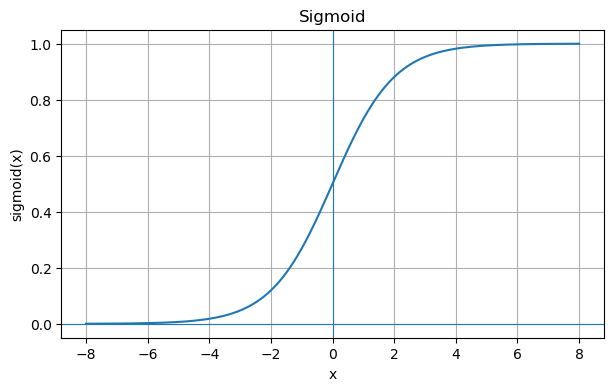

In [2]:
x = torch.linspace(-8, 8, 300)
s = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), s.numpy())
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("x")
plt.ylabel("sigmoid(x)")
plt.title("Sigmoid")
plt.grid(True)
plt.show()

## 2.1. Derivative of Sigmoid

$$
\sigma'(x)=\sigma(x)(1-\sigma(x))
$$

The maximum derivative is only about `0.25`.

For large positive or negative inputs, the derivative becomes close to zero. This is one reason sigmoid can contribute to the **vanishing gradient** problem.

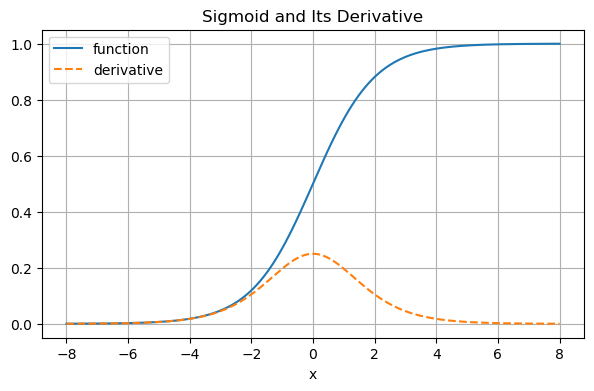

sigmoid(0) = 0.5
sigmoid'(0) = 0.25


In [3]:
x = torch.linspace(-8, 8, 300)
s = torch.sigmoid(x)
ds = s * (1 - s)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), s.numpy(), label="function")
plt.plot(x.numpy(), ds.numpy(), "--", label="derivative")
plt.xlabel("x")
plt.title("Sigmoid and Its Derivative")
plt.legend()
plt.grid(True)
plt.show()

print("sigmoid(0) =", torch.sigmoid(torch.tensor(0.0)).item())
print("sigmoid'(0) =", 0.25)

# 3. Tanh

$$
\tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}
$$

Its output lies in:

$$
-1 < \tanh(x) < 1
$$

Unlike sigmoid, `tanh` is centered around zero.

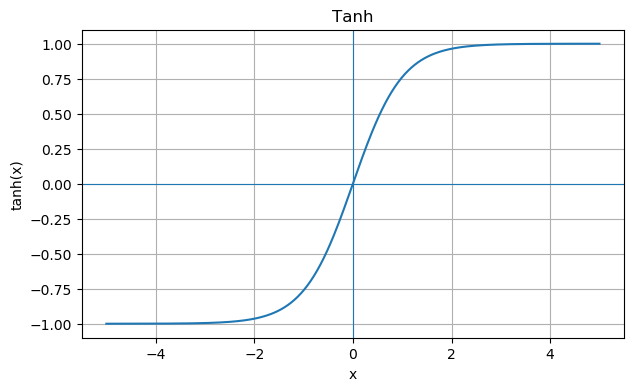

In [4]:
x = torch.linspace(-5, 5, 300)
t = torch.tanh(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), t.numpy())
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("x")
plt.ylabel("tanh(x)")
plt.title("Tanh")
plt.grid(True)
plt.show()

## 3.1. Derivative of Tanh

$$
\frac{d}{dx}\tanh(x)=1-\tanh^2(x)
$$

Near zero, the derivative can be close to `1`, but for large $|x|$ it also approaches zero.

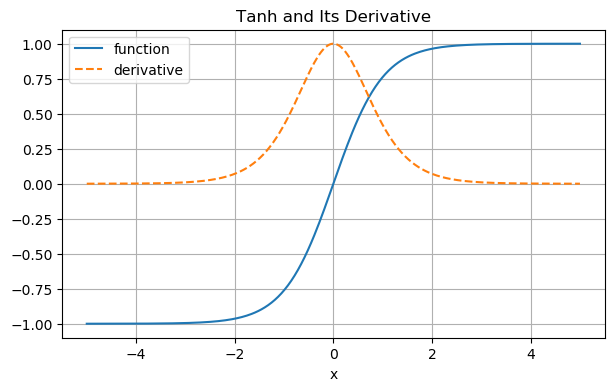

In [5]:
x = torch.linspace(-5, 5, 300)
t = torch.tanh(x)
dt = 1 - t**2

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), t.numpy(), label="function")
plt.plot(x.numpy(), dt.numpy(), "--", label="derivative")
plt.xlabel("x")
plt.title("Tanh and Its Derivative")
plt.legend()
plt.grid(True)
plt.show()

# 4. ReLU

$$
\operatorname{ReLU}(x)=\max(0,x)
$$

Equivalently:

$$
\operatorname{ReLU}(x)=
\begin{cases}
0, & x \le 0\\
x, & x>0
\end{cases}
$$

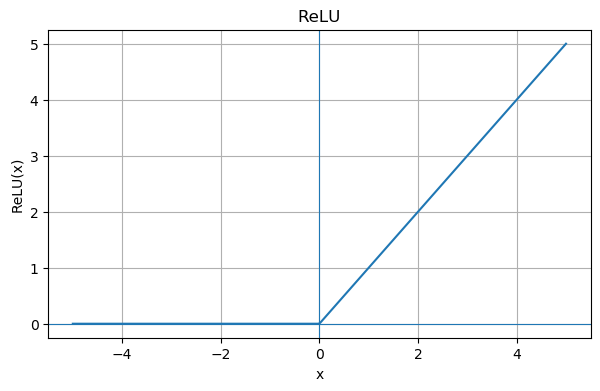

In [6]:
x = torch.linspace(-5, 5, 300)
r = torch.relu(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), r.numpy())
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("x")
plt.ylabel("ReLU(x)")
plt.title("ReLU")
plt.grid(True)
plt.show()

## 4.1. Derivative of ReLU

For teaching purposes:

$$
\operatorname{ReLU}'(x)=
\begin{cases}
0, & x<0\\
1, & x>0
\end{cases}
$$

At $x=0$, the mathematical derivative is undefined. In PyTorch, the gradient used for `ReLU` at `0` is `0`.

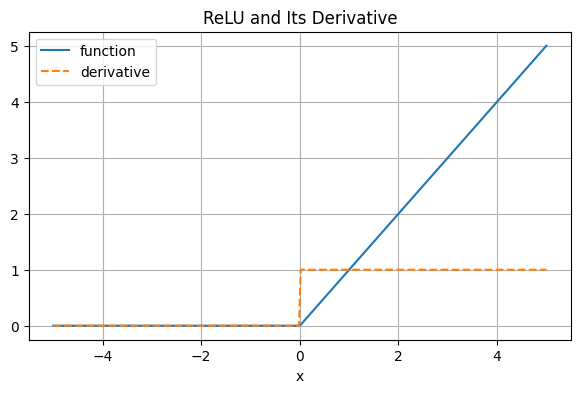

In [7]:
x = torch.linspace(-5, 5, 300)
r = torch.relu(x)
dr = (x > 0).float()

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), r.numpy(), label="function")
plt.plot(x.numpy(), dr.numpy(), "--", label="derivative")
plt.xlabel("x")
plt.title("ReLU and Its Derivative")
plt.legend()
plt.grid(True)
plt.show()

# 5. Comparing the Activations

| Function | Range | Strengths | Weaknesses |
|---|---|---|---|
| Sigmoid | $(0,1)$ | useful for probabilities | vanishing gradients |
| Tanh | $(-1,1)$ | zero-centered | can also saturate |
| ReLU | $[0,\infty)$ | simple, fast, widely used | zero gradient for $x<0$ |

For many simple hidden layers, `ReLU` is a common default starting point.

# 6. Activation Functions in PyTorch

```python
torch.sigmoid(x)
torch.tanh(x)
torch.relu(x)
```

Module versions:

```python
nn.Sigmoid()
nn.Tanh()
nn.ReLU()
```

In [8]:
values = torch.tensor([-2.0, 0.0, 2.0])

print("x       =", values)
print("sigmoid =", torch.sigmoid(values))
print("tanh    =", torch.tanh(values))
print("relu    =", torch.relu(values))

x       = tensor([-2.,  0.,  2.])
sigmoid = tensor([0.1192, 0.5000, 0.8808])
tanh    = tensor([-0.9640,  0.0000,  0.9640])
relu    = tensor([0., 0., 2.])


# 7. The Chain Rule Through an Activation

Suppose:

$$
z=wx+b
$$

$$
a=\sigma(z)
$$

and

$$
L=(a-y)^2
$$

Then:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial a}
\cdot
\frac{\partial a}{\partial z}
\cdot
\frac{\partial z}{\partial w}
$$

This is backpropagation through an activation function.

# 8. One Sigmoid Neuron — Manual Backpropagation

Take:

$$
x=2,\quad w=0.5,\quad b=0,\quad y=1
$$

### Forward

$$
z=wx+b
$$

$$
a=\sigma(z)
$$

$$
L=(a-y)^2
$$

### Backward

$$
\frac{\partial L}{\partial a}=2(a-y)
$$

$$
\frac{\partial a}{\partial z}=a(1-a)
$$

$$
\frac{\partial z}{\partial w}=x
$$

Therefore:

$$
\frac{\partial L}{\partial w}=2(a-y)\cdot a(1-a)\cdot x
$$

In [9]:
x = 2.0
w = 0.5
b = 0.0
target = 1.0

z = w*x + b
a = 1 / (1 + torch.exp(torch.tensor(-z))).item()
loss = (a - target)**2

dL_da = 2 * (a - target)
da_dz = a * (1 - a)
dz_dw = x

dL_dw = dL_da * da_dz * dz_dw

print("z =", z)
print("a =", a)
print("loss =", loss)
print("Manual gradient dL/dw =", dL_dw)

z = 1.0
a = 0.7310586055954523
loss = 0.07232947362426247
Manual gradient dL/dw = -0.21150833652482545


# 9. The Same Computation with PyTorch Autograd

```text
w
│
▼
z = wx + b
│
▼
sigmoid
│
▼
prediction
│
▼
loss
│
▼
backward()
│
▼
w.grad
```

In [10]:
x = torch.tensor(2.0)
target = torch.tensor(1.0)

w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

z = w*x + b
prediction = torch.sigmoid(z)
loss = (prediction - target)**2

loss.backward()

print("z =", z.item())
print("prediction =", prediction.item())
print("loss =", loss.item())
print("PyTorch gradient dL/dw =", w.grad.item())
print("dL/db =", b.grad.item())

z = 1.0
prediction = 0.7310585975646973
loss = 0.07232947647571564
PyTorch gradient dL/dw = -0.2115083485841751
dL/db = -0.10575417429208755


# 10. Diagram of a Neuron with Activation

$$
x \rightarrow wx+b \rightarrow \phi(z) \rightarrow \hat y \rightarrow L
$$

The activation block $\phi(z)$ introduces nonlinearity.

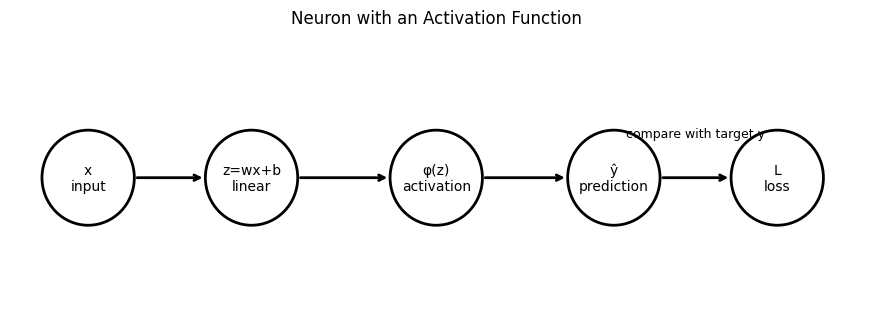

In [11]:
fig, ax = plt.subplots(figsize=(11,3.8))
ax.set_xlim(0,12)
ax.set_ylim(0,4)
ax.axis("off")

nodes = [
    ((1.1,2.0), "x\ninput"),
    ((3.4,2.0), "z=wx+b\nlinear"),
    ((6.0,2.0), "φ(z)\nactivation"),
    ((8.5,2.0), "ŷ\nprediction"),
    ((10.8,2.0), "L\nloss"),
]

for (cx,cy), label in nodes:
    circle = Circle((cx,cy),0.65,fill=False,linewidth=2)
    ax.add_patch(circle)
    ax.text(cx,cy,label,ha="center",va="center",fontsize=10)

for x1,x2 in [(1.75,2.75),(4.05,5.35),(6.65,7.85),(9.15,10.15)]:
    ax.annotate("",xy=(x2,2),xytext=(x1,2),arrowprops=dict(arrowstyle="->",lw=2))

ax.text(9.65,2.55,"compare with target y",ha="center",fontsize=9)
ax.set_title("Neuron with an Activation Function")
plt.show()

# 11. How ReLU Affects the Gradient

If $z>0$, the local derivative is `1`, so the gradient passes backward.

If $z<0$, the local derivative is `0`, so the gradient to previous parameters can become `0`.

In [12]:
for z_value in [2.0, -2.0, 0.0]:
    z = torch.tensor(z_value, requires_grad=True)
    a = torch.relu(z)
    a.backward()
    print(f"z={z_value:>4}: ReLU(z)={a.item():.1f}, gradient={z.grad.item():.1f}")

z= 2.0: ReLU(z)=2.0, gradient=1.0
z=-2.0: ReLU(z)=0.0, gradient=0.0
z= 0.0: ReLU(z)=0.0, gradient=0.0


# 12. Checking Autograd with a Numerical Derivative

$$
\frac{\partial L}{\partial w}
\approx
\frac{L(w+h)-L(w-h)}{2h}
$$

We can compare this approximation with PyTorch's gradient.

In [13]:
def loss_for_weight(weight):
    x = 2.0
    target = 1.0
    z = weight * x
    prediction = 1 / (1 + torch.exp(torch.tensor(-z))).item()
    return (prediction - target)**2

w0 = 0.5
h = 1e-4

numerical_gradient = (loss_for_weight(w0+h) - loss_for_weight(w0-h)) / (2*h)

w = torch.tensor(w0, requires_grad=True)
x = torch.tensor(2.0)
target = torch.tensor(1.0)
prediction = torch.sigmoid(w*x)
loss = (prediction-target)**2
loss.backward()

print("Numerical gradient =", numerical_gradient)
print("PyTorch gradient   =", w.grad.item())

Numerical gradient = -0.21161142341429018
PyTorch gradient   = -0.2115083485841751


# 13. A Small Network: Linear → ReLU → Linear

```text
input
  │
  ▼
Linear
  │
  ▼
ReLU
  │
  ▼
Linear
  │
  ▼
prediction
```

This is already a small neural network.

In [14]:
model = nn.Sequential(
    nn.Linear(2,3),
    nn.ReLU(),
    nn.Linear(3,1)
)

X = torch.tensor([
    [1.0,2.0],
    [2.0,1.0],
    [3.0,4.0]
])

y = torch.tensor([[1.0],[0.0],[1.0]])

prediction = model(X)
loss = ((prediction-y)**2).mean()

print(model)
print("\nPrediction:")
print(prediction)
print("\nLoss:", loss.item())

Sequential(
  (0): Linear(in_features=2, out_features=3, bias=True)
  (1): ReLU()
  (2): Linear(in_features=3, out_features=1, bias=True)
)

Prediction:
tensor([[0.7049],
        [0.2832],
        [0.2327]], grad_fn=<AddmmBackward0>)

Loss: 0.2519999146461487


## 13.1. What Happens to the Gradients?

After:

```python
loss.backward()
```

every trainable parameter receives its own `.grad`.

PyTorch applies the chain rule through the second `Linear`, through `ReLU`, and through the first `Linear`.

In [15]:
model.zero_grad()
loss.backward()

for name, parameter in model.named_parameters():
    print(name)
    print("shape:", tuple(parameter.shape))
    print("grad shape:", tuple(parameter.grad.shape))
    print("mean |grad|:", parameter.grad.abs().mean().item())
    print()

0.weight
shape: (3, 2)
grad shape: (3, 2)
mean |grad|: 0.6208271980285645

0.bias
shape: (3,)
grad shape: (3,)
mean |grad|: 0.17894548177719116

2.weight
shape: (1, 3)
grad shape: (1, 3)
mean |grad|: 1.25421142578125

2.bias
shape: (1,)
grad shape: (1,)
mean |grad|: 0.5194617509841919



# 14. Bonus: Leaky ReLU

$$
\operatorname{LeakyReLU}(x)=
\begin{cases}
x, & x>0\\
\alpha x, & x\le0
\end{cases}
$$

For negative values, the gradient is no longer exactly zero.

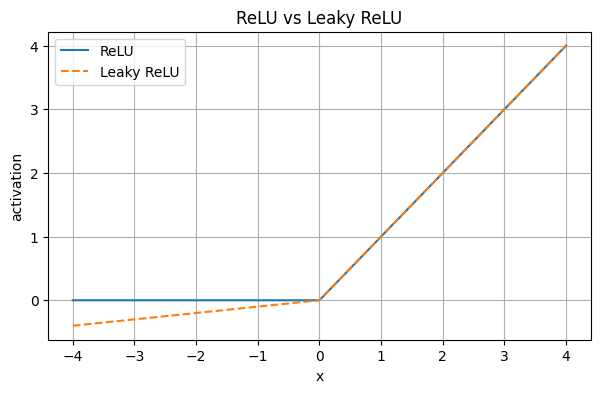

In [16]:
x = torch.linspace(-4,4,300)
r = torch.relu(x)
lr = torch.nn.functional.leaky_relu(x, negative_slope=0.1)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), r.numpy(), label="ReLU")
plt.plot(x.numpy(), lr.numpy(), "--", label="Leaky ReLU")
plt.xlabel("x")
plt.ylabel("activation")
plt.title("ReLU vs Leaky ReLU")
plt.legend()
plt.grid(True)
plt.show()

# Checks

# 15. Small Exercises

### Exercise 1
Compute manually:

$$
\sigma(0)
$$

and

$$
\sigma'(0)
$$

### Exercise 2
Change the one-neuron example to:

```python
w = -2.0
```

and observe how `z`, sigmoid output, and `w.grad` change.

### Exercise 3
Replace `Sigmoid` with `ReLU` and compare gradients for:

```python
z = 2
z = -2
```

### Exercise 4
In the small network, replace:

```python
nn.ReLU()
```

with:

```python
nn.Tanh()
```

and confirm that `loss.backward()` still works automatically.

In [17]:
x = torch.tensor(0.0, requires_grad=True)
y = torch.sigmoid(x)
y.backward()

print("sigmoid(0) =", y.item())
print("sigmoid'(0) =", x.grad.item())

sigmoid(0) = 0.5
sigmoid'(0) = 0.25


# 16. Quick Cheat Sheet

| Concept | Meaning |
|---|---|
| activation function | adds nonlinearity |
| Sigmoid | maps values to $(0,1)$ |
| Tanh | maps values to $(-1,1)$ |
| ReLU | returns `0` for negative inputs and `x` for positive inputs |
| local derivative | derivative of one operation |
| chain rule | multiplies local derivatives along a path |
| backpropagation | efficiently applies the chain rule from loss to parameters |
| vanishing gradient | gradients become very small |
| saturation | changing the input barely changes the output |

# Next Steps

We now have all the basic parts of a neuron:

$$
z=wx+b
$$

$$
a=\phi(z)
$$

and we know how gradients pass backward through $\phi$.

## ➡️ Next Notebook

### [Part 3 — Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/small-neural-network-pytorch)

We will cover:

- input layer;
- hidden layer;
- output layer;
- `nn.Linear`;
- activation functions;
- `forward()`;
- a mini training loop;
- visualization of network behavior.

### Full Series

1. [Part 1 — Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/pytorch-derivatives-gradients-backprop)  
2. **Part 2 — Activation Functions and the Chain Rule** ← you are here  
3. [Part 3 — Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/small-neural-network-pytorch)  
4. [Part 4 — Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/loss-gradient-descent-optimization)  
5. [Part 5 — Training Neural Networks End-to-End in PyTorch](https://www.kaggle.com/code/kupershtein/end-to-end-neural-network-training)

### Suggested Kaggle tags

`pytorch` · `deep-learning` · `activation-functions` · `autograd` · `backpropagation` · `neural-networks` · `mathematics`